# 18. Restrição territorial e concordância textual

O pareamento pela chave de logradouro e número não usa bairro nem CEP. Esses dois campos ficam livres para servir de verificação independente da correspondência e para testar o que acontece quando passam a ser exigidos. Este notebook responde a cinco perguntas.

1. Bairro e CEP concordam nos pares formados pela chave? Como essa concordância varia com a distância e entre as classes de evidência da cauda?
2. Exigir bairro, CEP ou ambos reduz a cauda de grandes distâncias porque melhora as correspondências ou porque exclui registros?
3. Quanto de cobertura cada restrição custa nos apartamentos, nos estabelecimentos e nas vilas e favelas?
4. Que parte dos pares de cada segmento tem um único lote fiscal vinculado, condição para medir a distância ao lote?
5. Como fica a composição da cauda num recorte comparável ao de Salles et al. (2025), que pareou por logradouro, número, bairro e CEP e inspecionou pares a mais de 150 m?

As entradas são as bases processadas do [NB01](01_ingestao.ipynb), o pareamento pela chave do [NB02](02_matching.ipynb) e as classes de evidência e a distância ponto a lote do [NB16](16_adjudicacao_cadastral.ipynb). As tabelas saem em `outputs/tables` e as figuras em `outputs/figures`, com o prefixo `nb18_`. O próximo notebook é o [NB22](22_conjuntos_exclusivos.ipynb), que examina as chaves sem par.

## 1. Reconstrução do pareamento pela chave

Para comparar regras, é preciso reconstruir o pareamento com todos os candidatos e com os atributos territoriais de cada lado. A chave combina o logradouro canônico, depois da conciliação de grafia, com a primeira sequência de dígitos do número. Para cada registro do CNEFE, todos os pontos do BHMap com a mesma chave são candidatos, e o mais próximo é o escolhido. Bairros são normalizados como os logradouros, e CEPs valem só com oito dígitos e diferentes de zero. A reconstrução precisa reproduzir exatamente as distâncias e os pontos de referência gravados pelo NB02.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from rapidfuzz import fuzz
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT))
from src import config
from src.metrics import chave_identidade, separar_logradouro_numero, conciliar_logradouros
from src.normalize import normalize_logradouro
P, T, F = config.PROCESSED_DIR, config.TAB_DIR, config.FIG_DIR
for d in (T, F): d.mkdir(parents=True, exist_ok=True)
SAIDAS_NB16 = config.TAB_DIR

C = gpd.read_parquet(P/'cnefe_bh.parquet')
B = gpd.read_parquet(P/'bhmap_bh.parquet')
I = pd.read_parquet(P/'cnefe_identidade.parquet')
assert I.index.equals(C.index) and C.index.is_unique and B.index.is_unique
assert len(B) == 757113
lc, nc = chave_identidade(*separar_logradouro_numero(C.LOGRAD_NUM))
lb, nb = chave_identidade(B.SIGLA_TIPO.fillna('')+' '+B.NOME_LOGRA.fillna(''), B.NUMERO_IMO)
mapa = conciliar_logradouros(lc.unique(), lb.unique(), 90, 2)
lc = lc.map(lambda x: mapa.get(x, x)).astype('string[python]')
nc, lb, nb = [s.astype('string[python]') for s in (nc, lb, nb)]
kc = (lc+'|'+nc).where(lc.notna() & lc.ne('') & nc.notna())
kb = (lb+'|'+nb).where(lb.notna() & lb.ne('') & nb.notna())

def cep(s):
    x = s.astype('string[python]').str.replace(r'\.0$', '', regex=True).str.replace(r'\D', '', regex=True).str.zfill(8)
    return x.where(x.str.fullmatch(r'\d{8}', na=False) & x.ne('00000000'))
def bairro(s):
    return s.map(lambda v: normalize_logradouro(v) if pd.notna(v) else pd.NA).astype('string[python]').replace('', pd.NA)

A = pd.DataFrame({'idx': C.index, 'chave': kc.to_numpy(), 'xc': C.geometry.x.to_numpy(), 'yc': C.geometry.y.to_numpy(),
                  'bairro_c': bairro(C.DSC_LOCALIDADE).to_numpy(), 'cep_c': cep(C.CEP).to_numpy()})
R = pd.DataFrame({'idx_b': B.index, 'chave': kb.to_numpy(), 'xb': B.geometry.x.to_numpy(), 'yb': B.geometry.y.to_numpy(),
                  'bairro_b': bairro(B.NOME_BAIRR).to_numpy(), 'cep_b': cep(B.CEP).to_numpy()})
J = A.dropna(subset=['chave']).merge(R.dropna(subset=['chave']), on='chave', how='inner')
J['dist'] = np.hypot(J.xc-J.xb, J.yc-J.yb)
base = J.loc[J.groupby('idx').dist.idxmin()].set_index('idx').sort_index()
assert len(base) == 1062044
assert np.allclose(base.dist, I.dist_identidade.reindex(base.index), atol=1e-8)
assert np.allclose(base.xb, I.ref_x.reindex(base.index), atol=1e-8) and np.allclose(base.yb, I.ref_y.reindex(base.index), atol=1e-8)
print(f'Registros do CNEFE: {len(C):,} | pontos existentes do BHMap: {len(B):,}')
print(f'Candidatos com a mesma chave: {len(J):,} | pares reconstruídos: {len(base):,}')

Registros do CNEFE: 1,180,102 | pontos existentes do BHMap: 757,113
Candidatos com a mesma chave: 1,485,150 | pares reconstruídos: 1,062,044


A reconstrução reproduz os 1.062.044 pares do NB02, com distâncias e pontos de referência idênticos. Os 1.485.150 candidatos mostram que parte das chaves tem mais de um ponto no BHMap, e é entre esses pontos que as regras das seções seguintes escolhem.

## 2. Concordância de bairro e CEP nos pares

Se a chave liga registros que descrevem o mesmo endereço, bairro e CEP devem coincidir na maior parte dos pares próximos. Se liga homônimos em partes diferentes da cidade, a concordância deve cair com a distância. A similaridade de bairro usa token sort ratio de pelo menos 90 sobre os nomes normalizados, para tolerar variações de grafia, e o CEP exige igualdade. Cada percentual tem como denominador os pares com o atributo válido nos dois lados. Cruzamos a concordância com as faixas de distância e com as classes de evidência da cauda acima de 100 m atribuídas no NB16.

In [2]:
base['bairro_disponivel'] = base.bairro_c.notna() & base.bairro_b.notna()
base['cep_disponivel'] = base.cep_c.notna() & base.cep_b.notna()
pares_bairros = base.loc[base.bairro_disponivel, ['bairro_c', 'bairro_b']].drop_duplicates()
semelhante = {(a, b): fuzz.token_sort_ratio(a, b) >= 90 for a, b in pares_bairros.itertuples(index=False, name=None)}
base['mesmo_bairro'] = [semelhante.get((a, b), np.nan) for a, b in zip(base.bairro_c, base.bairro_b)]
base['mesmo_cep'] = base.cep_c.eq(base.cep_b).where(base.cep_disponivel)
base['faixa'] = pd.cut(base.dist, [-1, 10, 30, 100, 1000, np.inf], labels=['até 10 m', '10 a 30 m', '30 a 100 m', '100 m a 1 km', 'acima de 1 km'])

def resumo_texto(g):
    return pd.Series({'pares': len(g), 'n_bairro': int(g.bairro_disponivel.sum()), 'mesmo_bairro_pct': 100*g.mesmo_bairro.mean(),
                      'n_cep': int(g.cep_disponivel.sum()), 'mesmo_cep_pct': 100*g.mesmo_cep.mean()})
por_faixa = base.groupby('faixa', observed=True).apply(resumo_texto, include_groups=False)
cauda = pd.read_parquet(SAIDAS_NB16/'nb16_cauda_adjudicada.parquet')
assert len(cauda) == 29775
por_classe = base.join(cauda[['veredito']]).dropna(subset=['veredito']).groupby('veredito').apply(resumo_texto, include_groups=False)
por_faixa.to_csv(T/'nb18_texto_por_faixa.csv')
por_classe.to_csv(T/'nb18_texto_por_classe.csv')
base.reset_index()[['idx', 'idx_b', 'chave', 'dist', 'mesmo_bairro', 'mesmo_cep']].to_parquet(T/'nb18_pares_concordancia.parquet', index=False)
print(por_faixa.round(1).to_string())
print()
print(por_classe.sort_values('pares', ascending=False).round(1).to_string())

                  pares  n_bairro  mesmo_bairro_pct     n_cep  mesmo_cep_pct
faixa                                                                       
até 10 m       539913.0  539913.0              92.7  538954.0           93.7
10 a 30 m      391803.0  391803.0              92.7  390876.0           91.2
30 a 100 m     100553.0  100553.0              91.3  100360.0           88.8
100 m a 1 km    21674.0   21674.0              82.3   21612.0           88.2
acima de 1 km    8101.0    8101.0               1.0    7705.0            7.1

                                    pares  n_bairro  mesmo_bairro_pct   n_cep  mesmo_cep_pct
veredito                                                                                    
imovel extenso, mesmo lote         9521.0    9521.0              87.0  9521.0           90.2
CNEFE fora do lote fiscal          7662.0    7662.0              84.6  7661.0           84.2
homonimia, chave em dois lugares   5515.0    5515.0               8.1  5214.0           

A concordância acompanha a distância. Até 100 m, bairro e CEP coincidem em 89% a 94% dos pares. Entre 100 m e 1 km, o bairro cai para 82,3% e o CEP fica em 88,2%. Acima de 1 km, quase não há concordância, com 1,0% de bairros iguais e 7,1% de CEPs iguais. Esses pares distantes ligam endereços com o mesmo logradouro e número em partes diferentes da cidade, o que indica correspondência errada, e não deslocamento da coordenada.

Nas classes da cauda, a concordância separa dois grupos. Nos imóveis extensos (87,0% de bairros e 90,2% de CEPs iguais) e nos pontos do CNEFE fora do lote (84,6% e 84,2%), os dois pontos estão no mesmo território. Isso é compatível com representações diferentes do mesmo imóvel ou com uma coordenada deslocada perto do endereço certo. Nas chaves ambíguas, só 8,1% dos bairros e 13,8% dos CEPs coincidem, como se espera de homônimos. As classes sem vínculo fiscal ficam entre os dois grupos.

## 3. Pareamento com restrição territorial

Refazemos a escolha do candidato exigindo, além da chave, a igualdade do bairro normalizado, a do CEP válido ou as duas. Não se trata de filtrar os pares já escolhidos. O candidato é escolhido de novo no conjunto restrito. Como o conjunto restrito está contido no original, cujo candidato mais próximo já tinha sido escolhido, nenhum registro mantido pode ficar mais perto. A redução da cauda, então, só pode vir de registros excluídos, descontadas as novas entradas quando o candidato muda. O código confere essa identidade contábil para os limiares de 100 m e de 1 km.

In [3]:
m_bairro = (J.bairro_c.notna() & J.bairro_b.notna() & J.bairro_c.eq(J.bairro_b)).fillna(False)
m_cep = (J.cep_c.notna() & J.cep_b.notna() & J.cep_c.eq(J.cep_b)).fillna(False)
regras = {'logradouro_numero': np.ones(len(J), dtype=bool), 'mais_bairro': m_bairro, 'mais_cep': m_cep, 'mais_bairro_e_cep': m_bairro & m_cep}
selecionados, linhas = {}, []
for nome, mascara in regras.items():
    cand = J.loc[mascara]
    melhor = cand.loc[cand.groupby('idx').dist.idxmin()].set_index('idx').sort_index()
    selecionados[nome] = melhor
    antes = base.dist.reindex(melhor.index)
    delta = melhor.dist-antes
    assert delta.ge(-1e-8).all()
    linha = {'regra': nome, 'pares': len(melhor), 'cobertura_pct': 100*len(melhor)/len(C),
             'mediana_m': melhor.dist.median(), 'p90_m': melhor.dist.quantile(.9),
             'candidato_alterado': int(melhor.idx_b.ne(base.idx_b.reindex(melhor.index)).sum()),
             'distancia_aumentou': int(delta.gt(1e-8).sum())}
    for lim in [100, 1000]:
        origem = int(base.dist.gt(lim).sum())
        excluidos = int(base.loc[~base.index.isin(melhor.index), 'dist'].gt(lim).sum())
        entradas = int((antes.le(lim) & melhor.dist.gt(lim)).sum())
        final = int(melhor.dist.gt(lim).sum())
        assert final == origem-excluidos+entradas
        linha.update({f'cauda{lim}_original': origem, f'cauda{lim}_excluida': excluidos, f'cauda{lim}_entrada': entradas, f'cauda{lim}_final': final})
    linhas.append(linha)
restricao = pd.DataFrame(linhas)
restricao.to_csv(T/'nb18_restricao_territorial.csv', index=False)
print(restricao[['regra', 'pares', 'cobertura_pct', 'mediana_m', 'p90_m', 'candidato_alterado', 'distancia_aumentou']].round(2).to_string(index=False))
print()
print(restricao[['regra']+[c for c in restricao.columns if c.startswith('cauda')]].to_string(index=False))

            regra   pares  cobertura_pct  mediana_m  p90_m  candidato_alterado  distancia_aumentou
logradouro_numero 1062044          90.00       9.84  35.59                   0                   0
      mais_bairro  972070          82.37       9.73  32.94                 462                 462
         mais_cep  971505          82.32       9.63  33.14                1500                1500
mais_bairro_e_cep  900004          76.26       9.59  32.06                 420                 420

            regra  cauda100_original  cauda100_excluida  cauda100_entrada  cauda100_final  cauda1000_original  cauda1000_excluida  cauda1000_entrada  cauda1000_final
logradouro_numero              29775                  0                 0           29775                8101                   0                  0             8101
      mais_bairro              29775              11875               110           18010                8101                8020                  0               81
      

Exigir bairro quase elimina os pares a mais de 1 km, que caem de 8.101 para 81. A identidade contábil mostra como isso acontece. Saem 8.020 pares distantes por exclusão, e nenhum entra. Com CEP, saem 7.431 e entram 1.192, porque a troca de candidato leva alguns registros a um ponto mais distante com o mesmo CEP, e o total fica em 1.862. Em nenhuma regra um registro mantido ficou mais perto. Os que mudam de candidato, 462 com bairro e 1.500 com CEP, ficaram todos mais longe.

A mediana quase não muda, de 9,84 m para cerca de 9,6 m a 9,7 m, e o P90 cai de 35,6 m para cerca de 32 m a 33 m, efeito da saída da cauda. O preço é a cobertura, que cai de 90,0% para 82,4% com bairro, 82,3% com CEP e 76,3% com os dois.

## 4. Cobertura por segmento e elegibilidade por lote

O custo de uma regra mais estrita não se distribui igualmente pela cidade. Medimos, para cada regra, a parcela de registros com par em seis segmentos: todos, apartamentos, estabelecimentos, demais tipos (registros que não são apartamentos nem estabelecimentos, incluindo edificações em construção) e registros dentro e fora das vilas e favelas mapeadas. O denominador é sempre o total de registros do segmento. Medimos também que parte dos pares de cada segmento tem a chave vinculada a um único lote fiscal, condição usada no NB16 para comparar a distância ao ponto com a distância ao lote.

regra             logradouro_numero  mais_bairro  mais_cep  mais_bairro_e_cep
segmento                                                                     
apartamentos                   95.5         90.6      87.3               83.2
demais_tipos                   87.3         77.7      80.4               73.0
em_vila                        72.3         52.4      56.3               42.7
estabelecimentos               86.4         79.8      76.4               71.1
fora_vila                      92.1         86.0      85.5               80.4
todos                          90.0         82.4      82.3               76.3

        segmento  pareados  com_lote_unico  com_lote_unico_pct
           todos   1062044          808059                76.1
    apartamentos    385346          363643                94.4
    demais_tipos    561288          367131                65.4
estabelecimentos    115410           77285                67.0
         em_vila     92694           11784                12

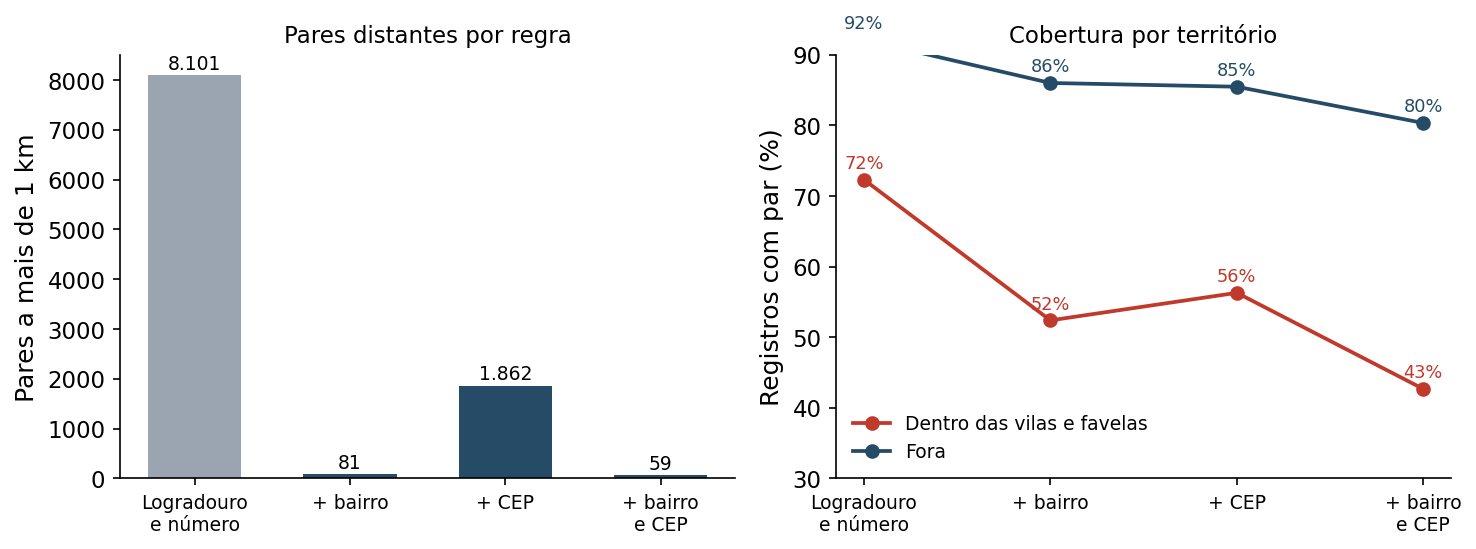

In [4]:
vila = gpd.read_parquet(P/'vila_favela.parquet', columns=['geometry'])
assert C.crs == vila.crs
em_vila = pd.Series(shapely.within(C.geometry.to_numpy(), vila.geometry.union_all()), index=C.index)
apto = pd.to_numeric(C.COD_TIPO_ESPECI, errors='coerce').eq(103).fillna(False)
estab = pd.to_numeric(C.COD_ESPECIE, errors='coerce').isin([3, 4, 5, 6, 8]).fillna(False)
assert not (apto & estab).any() and int(em_vila.sum()) == 128149
segmentos = {'todos': pd.Series(True, index=C.index), 'apartamentos': apto, 'demais_tipos': ~apto & ~estab,
             'estabelecimentos': estab, 'em_vila': em_vila, 'fora_vila': ~em_vila}
linhas = []
for nome, melhor in selecionados.items():
    for seg, m in segmentos.items():
        ids = C.index[m]
        pareados = melhor.index.intersection(ids)
        originais = base.index.intersection(ids)
        linhas.append({'regra': nome, 'segmento': seg, 'registros': len(ids), 'pareados': len(pareados),
                       'cobertura_pct': 100*len(pareados)/len(ids), 'perda_pp': 100*(len(originais)-len(pareados))/len(ids)})
cobertura = pd.DataFrame(linhas)
cobertura.to_csv(T/'nb18_cobertura_segmentos.csv', index=False)
ponto_lote = pd.read_parquet(SAIDAS_NB16/'nb16_ponto_lote_pares.parquet')
assert len(ponto_lote) == 808059
elegibilidade = pd.DataFrame([{'segmento': seg, 'pareados': len(base.index.intersection(C.index[m])),
                               'com_lote_unico': len(ponto_lote.index.intersection(C.index[m]))} for seg, m in segmentos.items()])
elegibilidade['com_lote_unico_pct'] = 100*elegibilidade.com_lote_unico/elegibilidade.pareados
elegibilidade.to_csv(T/'nb18_elegibilidade_lote.csv', index=False)
print(cobertura.pivot(index='segmento', columns='regra', values='cobertura_pct')[list(regras)].round(1).to_string())
print()
print(elegibilidade.round(1).to_string(index=False))

rotulos = {'logradouro_numero': 'Logradouro\ne número', 'mais_bairro': '+ bairro', 'mais_cep': '+ CEP', 'mais_bairro_e_cep': '+ bairro\ne CEP'}
x = np.arange(len(regras))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].bar(x, restricao.set_index('regra').loc[list(regras), 'cauda1000_final'], color=['#9AA5B1', '#264B67', '#264B67', '#264B67'], width=.6)
for xi, v in zip(x, restricao.set_index('regra').loc[list(regras), 'cauda1000_final']):
    ax[0].text(xi, v+120, f'{int(v):,}'.replace(',', '.'), ha='center', fontsize=9)
ax[0].set_xticks(x, [rotulos[r] for r in regras], fontsize=9)
ax[0].set_ylabel('Pares a mais de 1 km')
ax[0].set_title('Pares distantes por regra', fontsize=11)
for seg, cor, nome in [('em_vila', '#C0392B', 'Dentro das vilas e favelas'), ('fora_vila', '#264B67', 'Fora')]:
    s = cobertura[cobertura.segmento.eq(seg)].set_index('regra').loc[list(regras), 'cobertura_pct']
    ax[1].plot(x, s, marker='o', color=cor, lw=1.8, label=nome)
    for xi, v in zip(x, s):
        ax[1].text(xi, v+1.6, f'{v:.0f}%', ha='center', fontsize=8.5, color=cor)
ax[1].set_xticks(x, [rotulos[r] for r in regras], fontsize=9)
ax[1].set_ylabel('Registros com par (%)')
ax[1].set_ylim(30, 90)
ax[1].set_title('Cobertura por território', fontsize=11)
ax[1].legend(fontsize=9, frameon=False, loc='lower left')
for a in ax:
    a.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(F/'nb18_restricao_territorial.png', dpi=200)
plt.show()

A perda de cobertura é desigual. Com bairro, as vilas e favelas caem de 72,3% para 52,4%, uma perda de 19,9 pontos, contra 6,1 pontos no restante da cidade (de 92,1% para 86,0%). Exigir bairro e CEP deixa só 42,7% dos registros das vilas com par. A figura mostra as duas faces da mesma regra. À esquerda está a cauda distante que desaparece, e à direita a cobertura que se perde, muito mais dentro das vilas. Uma chave mais estrita parece mais consistente porque retira justamente os territórios onde a correspondência é mais difícil.

A elegibilidade para a medida ponto a lote também é desigual. Têm um único lote vinculado 94,4% dos pares de apartamentos, 82,1% dos pares fora das vilas e só 12,7% dos pares dentro delas. A comparação com o lote fiscal descreve, portanto, sobretudo a cidade formal.

## 5. Recorte comparável a Salles et al. (2025)

Salles et al. parearam o CNEFE com o cadastro municipal por logradouro, número, bairro e CEP, usaram apenas coordenadas de coleta original e inspecionaram visualmente 68 pares a mais de 150 m. Para comparar populações, tomamos os pares da cauda cujo bairro e CEP coincidem, com nível de coordenada igual a 1 no CNEFE e distância acima de 150 m, e vemos a distribuição das classes de evidência do NB16. As classes daqui vêm do lote fiscal e dos eixos de logradouro, e as daquele estudo vêm da inspeção em imagens. A comparação mostra como a seleção muda a composição, sem equiparar as categorias.

In [5]:
nivel = pd.read_parquet(P/'cnefe_bh.parquet', columns=['NV_GEO_COORD']).NV_GEO_COORD
cs = cauda.join(base[['mesmo_bairro', 'mesmo_cep']]).join(nivel.rename('nivel'))
recorte = cs[cs.mesmo_bairro.eq(True) & cs.mesmo_cep.eq(True) & cs.nivel.eq(1) & cs.dist.gt(150)]
salles = recorte.groupby(['natureza', 'veredito']).size().rename('pares').reset_index()
salles['pct'] = 100*salles.pares/len(recorte)
salles = salles.sort_values('pares', ascending=False)
salles.to_csv(T/'nb18_recorte_salles.csv', index=False)
geral = cauda.veredito.value_counts(normalize=True).mul(100).rename('pct_cauda_completa')
comparacao = salles.set_index('veredito')[['pares', 'pct']].join(geral)
print(f'Pares no recorte: {len(recorte):,} de {len(cauda):,} na cauda')
print(comparacao.round(1).to_string())

Pares no recorte: 5,020 de 29,775 na cauda
                                   pares   pct  pct_cauda_completa
veredito                                                          
CNEFE fora do lote fiscal           2633  52.5                25.7
imovel extenso, mesmo lote          1105  22.0                32.0
CNEFE fora da via nomeada            481   9.6                12.6
mesma via sem lote fiscal            480   9.6                 7.3
homonimia, chave em dois lugares     175   3.5                18.5
grafia conciliada sem confirmacao     72   1.4                 3.1
indeterminado                         42   0.8                 0.5
BHMap fora do lote fiscal             32   0.6                 0.3


O recorte reúne 5.020 dos 29.775 pares da cauda, e nele a composição muda bastante. Os pontos do CNEFE fora do lote passam de 25,7% para 52,5% e se tornam a maior classe. As chaves ambíguas caem de 18,5% para 3,5%, porque a exigência de bairro e CEP iguais retira quase todos os homônimos. Os imóveis extensos ficam em 22,0%. Quem parte desse recorte vê sobretudo coordenadas fora do lote, enquanto a cauda completa se divide em partes parecidas entre imóveis extensos, chaves ambíguas e pontos fora do lote. As duas leituras descrevem populações diferentes.

## Conclusão

Bairro e CEP confirmam a correspondência dos pares próximos e apontam os pares distantes, já que acima de 1 km quase nenhum par concorda nesses campos. Como critério obrigatório, porém, eles reduzem a cauda só por exclusão. Nenhum registro mantido fica mais perto, e a perda de cobertura nas vilas e favelas é mais de três vezes maior que no restante da cidade. A medida ponto a lote alcança 13% dos pares nas vilas e 82% fora delas. O recorte comparável a Salles et al. (2025) mostra que a seleção muda a composição da cauda, com os pontos fora do lote passando de um quarto para mais da metade.

As restrições territoriais servem, então, para examinar correspondências, e não para filtrá-las automaticamente. Usá-las para ordenar candidatos, em vez de excluí-los, fica como caminho a testar.

O [NB22](22_conjuntos_exclusivos.ipynb) trata das chaves que não encontram par numa das bases.